In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             accuracy_score, confusion_matrix)
from scipy.cluster.hierarchy import dendrogram, linkage

In [16]:
df = pd.read_excel('dataset2.xlsx')
X = df.drop(columns=['Segment ID'])

print("Number of rows:", df.shape[0])

print("\n--- Statistic Table ---")
stats = pd.DataFrame({
    'Count': X.count(),
    'Mean': X.mean(),
    'Median': X.median(),
    'Std Dev': X.std(),
    'Min': X.min(),
    'Max': X.max()
})
print(stats.round(6))

print("\n--- Correlation matrix of p1-p7 ---")
print(X.corr().round(6))

Number of rows: 4950

--- Statistic Table ---
    Count       Mean     Median   Std Dev        Min        Max
p1   4950  20.328029  20.371111  1.572540  16.689351  26.135580
p2   4950  19.239014  19.246013  1.232127  16.357362  25.325126
p3   4950  18.809483  18.672173  1.163050  16.123157  23.558515
p4   4950  18.436524  18.366056  1.145774  15.475555  22.755311
p5   4950  17.203730  17.194038  1.174865  13.545506  22.645332
p6   4950  15.656804  15.659412  1.383016  12.841122  21.794763
p7   4950  13.319737  12.859763  1.739288  10.474133  20.093362

--- Correlation matrix of p1-p7 ---
          p1        p2        p3        p4        p5        p6        p7
p1  1.000000  0.821473  0.472759  0.412601  0.267564 -0.122083 -0.204786
p2  0.821473  1.000000  0.803443  0.659495  0.394938 -0.014643 -0.184739
p3  0.472759  0.803443  1.000000  0.895817  0.546674  0.199367 -0.031882
p4  0.412601  0.659495  0.895817  1.000000  0.781612  0.355845  0.109171
p5  0.267564  0.394938  0.546674  0.7816

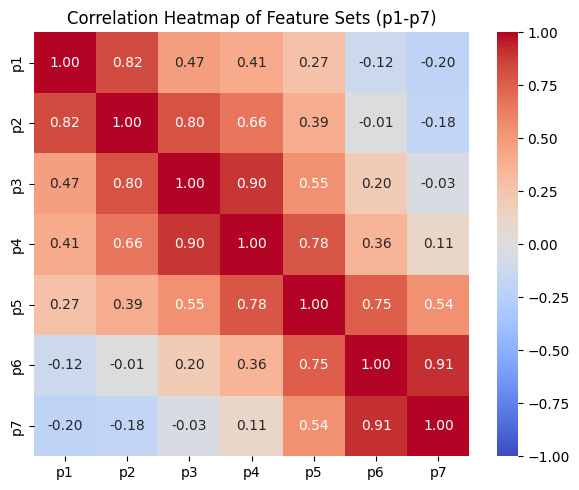

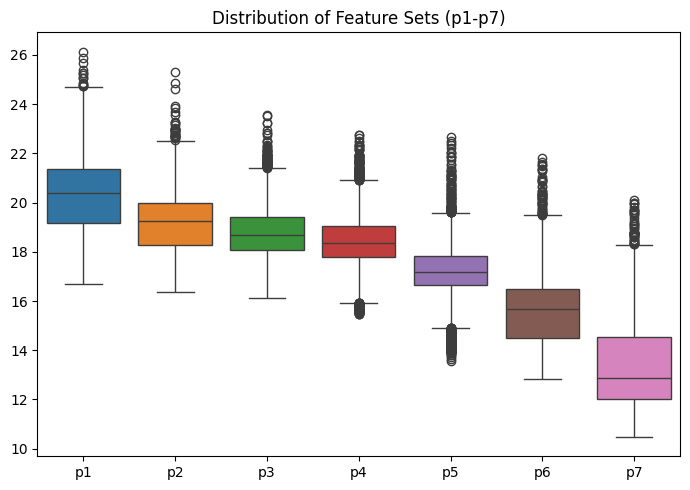

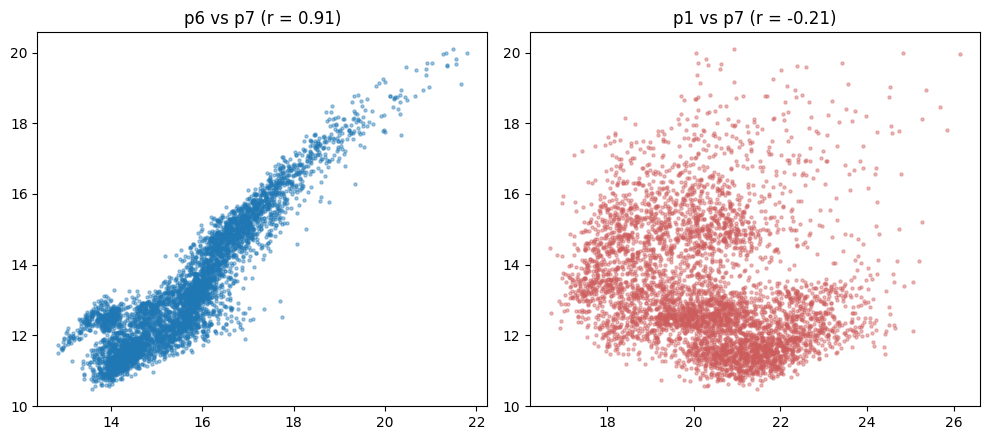

In [17]:
# 2.2 Data visualization
X = df.drop(columns=['Segment ID'])

# 1. Ma trận tương quan
plt.figure(figsize=(6,5))
sns.heatmap(X.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Feature Sets (p1-p7)')
plt.tight_layout()
plt.savefig('heatmap.png', dpi=150)

# 2. Phân phối giá trị từng feature set
plt.figure(figsize=(7,5))
sns.boxplot(data=X)
plt.title('Distribution of Feature Sets (p1-p7)')
plt.tight_layout()
plt.savefig('boxplot.png', dpi=150)

# 3. Scatter plot minh họa cặp tương quan cao nhất và thấp nhất
fig, axes = plt.subplots(1, 2, figsize=(10,4.5))
axes[0].scatter(X['p6'], X['p7'], s=5, alpha=0.4)
axes[0].set_title('p6 vs p7 (r = 0.91)')
axes[1].scatter(X['p1'], X['p7'], s=5, alpha=0.4, color='indianred')
axes[1].set_title('p1 vs p7 (r = -0.21)')
plt.tight_layout()
plt.savefig('scatter.png', dpi=150)

In [18]:
# 3.1 Preprocessing
df = pd.read_excel('dataset2.xlsx')
X = df.drop(columns=['Segment ID'])

# Giữ lại toàn bộ 7 feature sets (p1-p7)
print("Number of features:", X.shape[1])

# Chuẩn hóa dữ liệu bằng StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean after normalization:", X_scaled.mean(axis=0).round(3))
print("Std after normalization:", X_scaled.std(axis=0).round(3))

Number of features: 7
Mean after normalization: [-0. -0. -0.  0. -0.  0. -0.]
Std after normalization: [1. 1. 1. 1. 1. 1. 1.]


In [19]:
# 3.3 Helper functions used across the clustering analysis
def labels_to_AB(labels, ref_feature):
    """Map arbitrary cluster ids {0,1} to 'A'/'B' with a fixed rule so that
    results are directly comparable across methods: the cluster with the
    higher mean of the reference feature (p1) is always labelled 'A'."""
    high = 0 if ref_feature[labels == 0].mean() >= ref_feature[labels == 1].mean() else 1
    return np.where(labels == high, 'A', 'B')


def best_accuracy(pred_AB, truth):
    """Cluster ids carry no class meaning, so try both A/B -> class mappings
    and keep the one giving the higher accuracy.
    Returns (accuracy, aligned_predictions, mapping)."""
    best = (-1.0, None, None)
    for mapping in ({'A': 'Awake', 'B': 'Deep anaesthetic'},
                    {'A': 'Deep anaesthetic', 'B': 'Awake'}):
        pred = pd.Series(pred_AB).map(mapping)
        acc = accuracy_score(truth, pred)
        if acc > best[0]:
            best = (acc, pred, mapping)
    return best

In [20]:
# 3.4 K-Means clustering (k = 2) on all seven feature sets
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X_scaled)
km_AB = labels_to_AB(km_labels, X['p1'].values)

print("K-Means cluster sizes:")
print(pd.Series(km_AB).value_counts())
print("Inertia    :", round(kmeans.inertia_, 2))
print("Silhouette :", round(silhouette_score(X_scaled, km_labels), 4))

K-Means cluster sizes:
B    4023
A     927
Name: count, dtype: int64
Inertia    : 24736.1
Silhouette : 0.3546


Hierarchical cluster sizes:
B    4462
A     488
Name: count, dtype: int64
Silhouette : 0.3924


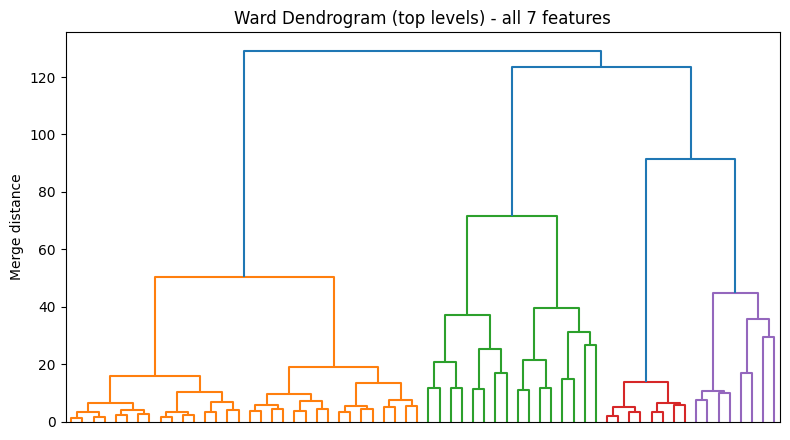

In [21]:
# Hierarchical clustering (Agglomerative, Ward) on all seven feature sets
hc = AgglomerativeClustering(n_clusters=2, linkage='ward')
hc_labels = hc.fit_predict(X_scaled)
hc_AB = labels_to_AB(hc_labels, X['p1'].values)

print("Hierarchical cluster sizes:")
print(pd.Series(hc_AB).value_counts())
print("Silhouette :", round(silhouette_score(X_scaled, hc_labels), 4))

# Dendrogram (top levels only, for readability)
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(8, 4.5))
dendrogram(Z, truncate_mode='level', p=5, no_labels=True)
plt.title('Ward Dendrogram (top levels) - all 7 features')
plt.ylabel('Merge distance')
plt.tight_layout()
plt.savefig('dendrogram.png', dpi=150)

In [22]:
# 3.6 Agreement between the two methods, all 7 features
agreement = (km_AB == hc_AB).mean()
ari = adjusted_rand_score(km_labels, hc_labels)

print(f"Agreement (same A/B label): {agreement:.4f}")
print(f"Adjusted Rand Index       : {ari:.4f}\n")
print("Cross-tabulation (rows = K-Means, cols = Hierarchical):")
print(pd.crosstab(pd.Series(km_AB, name='K-Means'),
                  pd.Series(hc_AB, name='Hierarchical')))

Agreement (same A/B label): 0.9113
Adjusted Rand Index       : 0.5677

Cross-tabulation (rows = K-Means, cols = Hierarchical):
Hierarchical    A     B
K-Means                
A             488   439
B               0  4023


In [23]:
# 4.1 Comparison with the ground-truth labels (Project data set 3), all 7 features
d3 = pd.read_excel('dataset3.xlsx')
truth = d3['label'].str.strip()   # 'Awake' / 'Deep anaesthetic'

for name, pred_AB in [('K-Means', km_AB), ('Hierarchical', hc_AB)]:
    acc, pred, mapping = best_accuracy(pred_AB, truth)
    print(f"=== {name} (all 7 features) ===")
    print("Best A/B -> class mapping:", mapping)
    print(f"Accuracy: {acc:.4f}")
    cm = confusion_matrix(truth, pred, labels=['Awake', 'Deep anaesthetic'])
    print(pd.DataFrame(cm, index=['Awake (true)', 'Deep (true)'],
                       columns=['Awake (pred)', 'Deep (pred)']), '\n')

=== K-Means (all 7 features) ===
Best A/B -> class mapping: {'A': 'Deep anaesthetic', 'B': 'Awake'}
Accuracy: 0.5113
              Awake (pred)  Deep (pred)
Awake (true)          2044          440
Deep (true)           1979          487 

=== Hierarchical (all 7 features) ===
Best A/B -> class mapping: {'A': 'Deep anaesthetic', 'B': 'Awake'}
Accuracy: 0.5693
              Awake (pred)  Deep (pred)
Awake (true)          2407           77
Deep (true)           2055          411 



In [24]:
# 4.2 Which feature set is more useful?
rows = []
for col in X.columns:
    xi = StandardScaler().fit_transform(X[[col]])
    lbl = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(xi)
    ab = labels_to_AB(lbl, X[col].values)
    acc, _, _ = best_accuracy(ab, truth)
    rows.append({'Feature': col,
                 'Silhouette': round(silhouette_score(xi, lbl), 3),
                 'Accuracy': round(acc, 3)})

feature_usefulness = pd.DataFrame(rows)
print(feature_usefulness.to_string(index=False))

Feature  Silhouette  Accuracy
     p1       0.558     0.770
     p2       0.562     0.670
     p3       0.574     0.514
     p4       0.521     0.516
     p5       0.490     0.542
     p6       0.569     0.849
     p7       0.658     0.791


In [25]:
# 4.3 Scenario B - re-run both methods on the SELECTED feature sets (evidence-based)
selected = ['p1', 'p6', 'p7']
Xs_sel = StandardScaler().fit_transform(X[selected])

km_sel = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(Xs_sel)
hc_sel = AgglomerativeClustering(n_clusters=2, linkage='ward').fit_predict(Xs_sel)
km_sel_AB = labels_to_AB(km_sel, X['p1'].values)
hc_sel_AB = labels_to_AB(hc_sel, X['p1'].values)

for name, pred_AB, lbl in [('K-Means', km_sel_AB, km_sel),
                           ('Hierarchical', hc_sel_AB, hc_sel)]:
    acc, pred, _ = best_accuracy(pred_AB, truth)
    print(f"=== {name} on {selected} ===")
    print(f"Accuracy: {acc:.4f} | Silhouette: {silhouette_score(Xs_sel, lbl):.3f}")
    cm = confusion_matrix(truth, pred, labels=['Awake', 'Deep anaesthetic'])
    print(pd.DataFrame(cm, index=['Awake (true)', 'Deep (true)'],
                       columns=['Awake (pred)', 'Deep (pred)']), '\n')

=== K-Means on ['p1', 'p6', 'p7'] ===
Accuracy: 0.9152 | Silhouette: 0.443
              Awake (pred)  Deep (pred)
Awake (true)          2105          379
Deep (true)             41         2425 

=== Hierarchical on ['p1', 'p6', 'p7'] ===
Accuracy: 0.9632 | Silhouette: 0.435
              Awake (pred)  Deep (pred)
Awake (true)          2358          126
Deep (true)             56         2410 



Explained variance ratio: [0.516 0.336 0.091 0.037 0.012 0.006 0.002]
Cumulative               : [0.516 0.853 0.943 0.98  0.992 0.998 1.   ] 

K-Means on PCA1: accuracy = 0.511
K-Means on PCA2: accuracy = 0.511
K-Means on PCA3: accuracy = 0.516


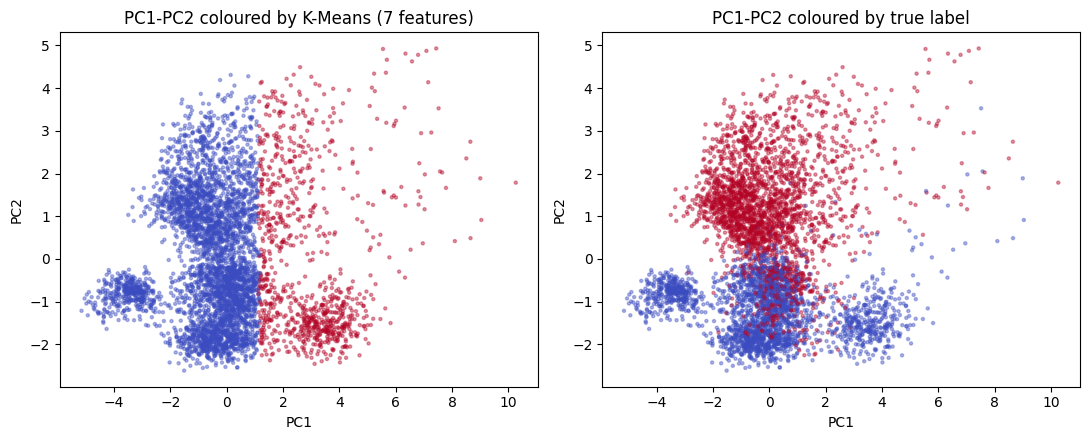

In [26]:
# 4.4 Does PCA help? (dimensionality reduction on all 7 features)
pca_full = PCA().fit(X_scaled)
print("Explained variance ratio:", pca_full.explained_variance_ratio_.round(3))
print("Cumulative               :", pca_full.explained_variance_ratio_.cumsum().round(3), "\n")

for k in (1, 2, 3):
    Xp = PCA(n_components=k, random_state=42).fit_transform(X_scaled)
    km_p = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(Xp)
    acc, _, _ = best_accuracy(labels_to_AB(km_p, X['p1'].values), truth)
    print(f"K-Means on PCA{k}: accuracy = {acc:.3f}")

# 2D PCA scatter: K-Means clusters vs true labels (visual comparison)
X2 = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(X2[:, 0], X2[:, 1], c=(km_AB == 'A'), s=5, alpha=0.4, cmap='coolwarm')
ax[0].set_title('PC1-PC2 coloured by K-Means (7 features)')
ax[1].scatter(X2[:, 0], X2[:, 1], c=(truth == 'Awake').values, s=5, alpha=0.4, cmap='coolwarm')
ax[1].set_title('PC1-PC2 coloured by true label')
for a in ax:
    a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.tight_layout()
plt.savefig('pca_scatter.png', dpi=150)

In [27]:
# 4.5 Export segment-level classification results to a spreadsheet (Appendix)
results = pd.DataFrame({
    'Segment ID': df['Segment ID'],
    'KMeans_7feat': km_AB,
    'Hier_7feat': hc_AB,
    'KMeans_selected': km_sel_AB,
    'Hier_selected': hc_sel_AB,
    'True label': truth
})
results.to_excel('clustering_results.xlsx', index=False)
print("Saved clustering_results.xlsx")
print(results.head())

Saved clustering_results.xlsx
   Segment ID KMeans_7feat Hier_7feat KMeans_selected Hier_selected  \
0           1            B          B               A             A   
1           2            B          B               A             A   
2           3            B          B               A             A   
3           4            B          B               A             A   
4           5            B          B               A             A   

         True label  
0  Deep anaesthetic  
1  Deep anaesthetic  
2  Deep anaesthetic  
3  Deep anaesthetic  
4  Deep anaesthetic  
